# 3d — Split-half reproducibility of the Year 4 structure–function PLSC

Checks whether the Year 4 PLSC latent dimensions (rs-FC × RNI, rs-FC × RND) are stable across independent halves of the sample.

**What it does, for each of `N_SPLITS` random splits:**
1. Splits participants into two halves **by family** (siblings stay together), **stratified by site**.
2. Within each half, re-runs the same residualization as `1b-plsc-clean.Rmd` (age + sex + handedness + scanner manufacturer + site as factors) — fit separately per half, so nothing leaks between halves.
3. Runs the PLSC core exactly as `tepPLS(center = TRUE, scale = "SS1")`: SVD of the cross-correlation matrix R = XᵀY.
4. Records, for LD1–LD5:
   - **Salience reproducibility**: |r| between half A and half B saliences (rs-FC P and RNI/RND Q). Absolute value because SVD signs are arbitrary.
   - **Out-of-sample latent correlation**: half B data projected onto half A's saliences, r(Lx, Ly) — compared with the in-sample value.
   - **% covariance** explained in each half.

No permutations or bootstraps are needed, so this runs in a minute or two on a laptop. Inputs: `derivatives/katie-y4-vars/{covariate,clean-rsfc,clean-rni,clean-rnd}.csv`. Outputs: `derivatives/katie-y4-vars/split-half/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DERIV = Path('..') / 'derivatives' / 'katie-y4-vars'
OUT = DERIV / 'split-half'
OUT.mkdir(exist_ok=True)

N_SPLITS = 100      # random family-aware split-halves
N_DIMS = 5          # latent dimensions to track
SEED = 2026
ID = 'participant_id'
CATEGORICAL = ['demo_sex_v2', 'handedness', 'mri_info_manufacturer', 'site_id_l']  # as in config.R (site enters as a factor)
NUMERICAL = ['interview_age']

## Load data (same files and participant order as `1b-plsc-clean.Rmd`)

In [2]:
cov = pd.read_csv(DERIV / 'covariate.csv')
blocks = {
    'rsfc': pd.read_csv(DERIV / 'clean-rsfc.csv'),
    'rni':  pd.read_csv(DERIV / 'clean-rni.csv'),
    'rnd':  pd.read_csv(DERIV / 'clean-rnd.csv'),
}
for k, df in blocks.items():
    assert (df[ID].values == cov[ID].values).all(), f'{k} rows not aligned with covariates'
X_all = {k: df.drop(columns=ID).to_numpy(float) for k, df in blocks.items()}
print(f"N = {len(cov)}; rs-FC {X_all['rsfc'].shape[1]} edges; RNI {X_all['rni'].shape[1]} ROIs; RND {X_all['rnd'].shape[1]} ROIs")
print(f"sites = {cov.site_id_l.nunique()}; families = {cov.rel_family_id.nunique()}")

N = 5034; rs-FC 78 edges; RNI 68 ROIs; RND 68 ROIs
sites = 21; families = 4447


## Helper functions

In [3]:
def design(c):
    """Covariate design matrix: intercept + numeric + dummy-coded factors (same model as resid_block() in 1b)."""
    parts = [np.ones((len(c), 1)), c[NUMERICAL].to_numpy(float)]
    for v in CATEGORICAL:
        parts.append(pd.get_dummies(c[v].astype(str), drop_first=True).to_numpy(float))
    return np.hstack(parts)

def residualize(Y, C):
    beta, *_ = np.linalg.lstsq(C, Y, rcond=None)
    return Y - C @ beta

def ss1(Y):
    """Center each column and scale to unit sum of squares (ExPosition 'SS1')."""
    Y = Y - Y.mean(0)
    return Y / np.sqrt((Y ** 2).sum(0))

def plsc(X, Y):
    """Core of tepPLS: SVD of R = X'Y on SS1-scaled blocks. Returns P (X saliences), Q (Y saliences), eigenvalues."""
    U, d, Vt = np.linalg.svd(X.T @ Y, full_matrices=False)
    return U, Vt.T, d ** 2

def prep(idx, block):
    """Residualize + SS1-scale both blocks within the given subset of participants."""
    C = design(cov.iloc[idx])
    return ss1(residualize(X_all['rsfc'][idx], C)), ss1(residualize(X_all[block][idx], C))

def abs_r(a, b):
    return abs(np.corrcoef(a, b)[0, 1])

## Sanity check: full-sample PLSC matches the saved R results

If this implementation matches `tepPLS`, the full-sample saliences should correlate ~1.0 with `rsfc_P-components.csv` / `*_Q-components.csv`, and % covariance should match `percent_variance_explained.csv`.

In [4]:
full = {}
all_idx = np.arange(len(cov))
for block in ['rni', 'rnd']:
    X, Y = prep(all_idx, block)
    P, Q, eig = plsc(X, Y)
    full[block] = dict(P=P, Q=Q, pct=100 * eig / eig.sum())
    P_r = pd.read_csv(DERIV / f'plsc-{block}' / 'rsfc_P-components.csv', index_col=0).to_numpy()
    Q_r = pd.read_csv(DERIV / f'plsc-{block}' / f'{block}_Q-components.csv', index_col=0).to_numpy()
    pve = pd.read_csv(DERIV / f'plsc-{block}' / 'percent_variance_explained.csv')
    print(block.upper(),
          '| P match:', [round(abs_r(P[:, k], P_r[:, k]), 4) for k in range(3)],
          '| Q match:', [round(abs_r(Q[:, k], Q_r[:, k]), 4) for k in range(3)],
          '| % cov (python):', np.round(full[block]['pct'][:3], 2), '(R):', pve.Percent_Variance.values[:3])

RNI | P match: [np.float64(1.0), np.float64(1.0), np.float64(1.0)] | Q match: [np.float64(1.0), np.float64(1.0), np.float64(1.0)] | % cov (python): [78.47  7.7   2.63] (R): [78.47  7.7   2.63]
RND | P match: [np.float64(1.0), np.float64(1.0), np.float64(1.0)] | Q match: [np.float64(1.0), np.float64(1.0), np.float64(1.0)] | % cov (python): [66.61  7.57  4.56] (R): [66.61  7.57  4.56]


## Family-aware, site-stratified split-halves

Each family is assigned to its (modal) site; within each site, families are shuffled and assigned greedily to whichever half is currently smaller, so halves are balanced in N within every site and no family is split.

In [5]:
fam_site = cov.groupby('rel_family_id').site_id_l.agg(lambda s: s.mode().iloc[0])
fam_size = cov.groupby('rel_family_id').size()
rows_by_fam = cov.groupby('rel_family_id').indices

def split_half(rng):
    half = {}
    for site, fams in fam_site.groupby(fam_site).groups.items():
        fams = rng.permutation(np.asarray(fams))
        n = [0, 0]
        for f in fams:
            h = int(n[1] < n[0]) if n[0] != n[1] else int(rng.integers(2))
            half[f] = h
            n[h] += fam_size[f]
    lab = cov.rel_family_id.map(half).to_numpy()
    return np.where(lab == 0)[0], np.where(lab == 1)[0]

a, b = split_half(np.random.default_rng(0))
print('example split sizes:', len(a), len(b),
      '| families shared across halves:', len(set(cov.rel_family_id.iloc[a]) & set(cov.rel_family_id.iloc[b])))

example split sizes: 2516 2518 | families shared across halves: 0


## Run the splits

In [6]:
rng = np.random.default_rng(SEED)
rows = []
for s in range(N_SPLITS):
    ia, ib = split_half(rng)
    for block in ['rni', 'rnd']:
        Xa, Ya = prep(ia, block); Xb, Yb = prep(ib, block)
        Pa, Qa, ea = plsc(Xa, Ya); Pb, Qb, eb = plsc(Xb, Yb)
        for k in range(N_DIMS):
            rows.append(dict(
                split=s, block=block, dim=k + 1,
                P_r=abs_r(Pa[:, k], Pb[:, k]),                      # rs-FC salience reproducibility
                Q_r=abs_r(Qa[:, k], Qb[:, k]),                      # RNI/RND salience reproducibility
                P_r_full=abs_r(Pa[:, k], full[block]['P'][:, k]),   # half A vs full sample
                Q_r_full=abs_r(Qa[:, k], full[block]['Q'][:, k]),
                lat_r_in=abs_r(Xb @ Pb[:, k], Yb @ Qb[:, k]),       # in-sample latent r (half B)
                lat_r_oos=abs_r(Xb @ Pa[:, k], Yb @ Qa[:, k]),      # out-of-sample: B projected on A's saliences
                pct_a=100 * ea[k] / ea.sum(), pct_b=100 * eb[k] / eb.sum()))
res = pd.DataFrame(rows)
res.to_csv(OUT / 'split-half-all-splits.csv', index=False)
print(f'{N_SPLITS} splits done')

100 splits done


## Summary (median [2.5th–97.5th percentile] across splits)

In [7]:
def fmt(x):
    return f'{np.median(x):.2f} [{np.percentile(x, 2.5):.2f}–{np.percentile(x, 97.5):.2f}]'

metrics = {'P_r': 'rs-FC salience |r| (A vs B)', 'Q_r': 'RNI/RND salience |r| (A vs B)',
           'lat_r_in': 'latent r in-sample', 'lat_r_oos': 'latent r out-of-sample', 'pct_a': '% covariance (half A)'}
summary = (res.groupby(['block', 'dim'])[list(metrics)].agg(fmt).rename(columns=metrics).reset_index())
summary['block'] = summary.block.str.upper()
summary.to_csv(OUT / 'split-half-summary.csv', index=False)
pd.set_option('display.width', 200)
summary

,block,dim,rs-FC salience |r| (A vs B),RNI/RND salience |r| (A vs B),latent r in-sample,latent r out-of-sample,% covariance (half A)
0,RND,1,0.73 [0.50–0.83],0.74 [0.51–0.83],0.15 [0.14–0.17],0.11 [0.07–0.13],59.97 [52.56–68.80]
1,RND,2,0.56 [0.12–0.76],0.48 [0.09–0.71],0.16 [0.14–0.17],0.06 [0.02–0.09],8.11 [5.75–10.93]
2,RND,3,0.18 [0.02–0.66],0.21 [0.02–0.60],0.15 [0.14–0.18],0.05 [0.01–0.09],5.42 [4.15–7.77]
3,RND,4,0.25 [0.02–0.70],0.23 [0.01–0.57],0.15 [0.13–0.18],0.06 [0.01–0.11],4.24 [3.04–5.50]
4,RND,5,0.16 [0.01–0.45],0.20 [0.01–0.53],0.16 [0.13–0.19],0.04 [0.00–0.09],2.98 [2.28–3.85]
5,RNI,1,0.80 [0.69–0.90],0.84 [0.72–0.91],0.16 [0.14–0.18],0.13 [0.10–0.16],74.16 [67.44–79.71]
6,RNI,2,0.82 [0.69–0.91],0.83 [0.67–0.91],0.20 [0.18–0.23],0.15 [0.10–0.20],7.48 [5.39–10.88]
7,RNI,3,0.28 [0.01–0.61],0.37 [0.03–0.69],0.17 [0.14–0.21],0.07 [0.02–0.11],3.31 [2.38–4.91]
8,RNI,4,0.28 [0.02–0.68],0.32 [0.03–0.70],0.18 [0.14–0.20],0.09 [0.02–0.12],2.49 [1.70–3.28]
9,RNI,5,0.21 [0.01–0.49],0.15 [0.02–0.58],0.16 [0.13–0.19],0.05 [0.01–0.11],1.89 [1.29–2.57]


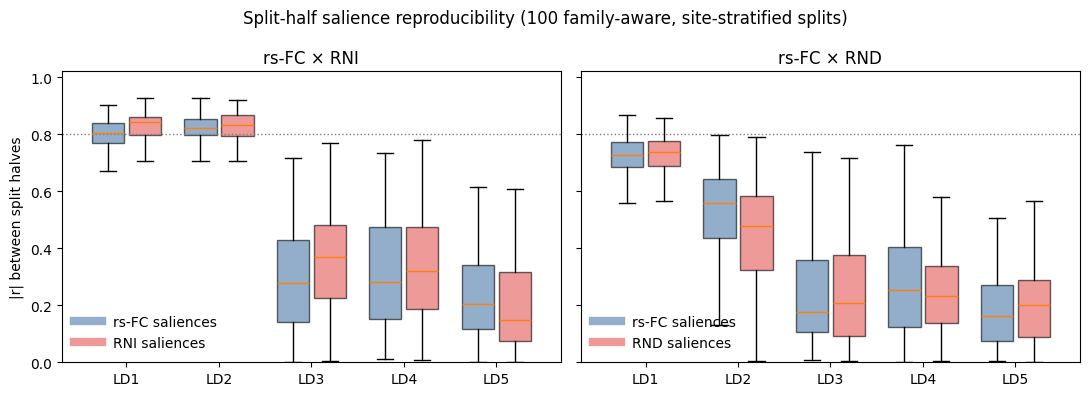

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, block in zip(axes, ['rni', 'rnd']):
    d = res[res.block == block]
    pos = np.arange(1, N_DIMS + 1)
    for off, col, lab, c in [(-0.2, 'P_r', 'rs-FC saliences', '#4C78A8'), (0.2, 'Q_r', f'{block.upper()} saliences', '#E45756')]:
        bp = ax.boxplot([d[d.dim == k][col] for k in pos], positions=pos + off, widths=0.35,
                        patch_artist=True, showfliers=False)
        for p in bp['boxes']: p.set(facecolor=c, alpha=0.6)
        ax.plot([], [], color=c, lw=6, alpha=0.6, label=lab)
    ax.set_xticks(pos, [f'LD{k}' for k in pos]); ax.set_title(f'rs-FC × {block.upper()}')
    ax.axhline(0.8, ls=':', c='grey', lw=1); ax.set_ylim(0, 1.02); ax.legend(loc='lower left', frameon=False)
axes[0].set_ylabel('|r| between split halves')
fig.suptitle(f'Split-half salience reproducibility ({N_SPLITS} family-aware, site-stratified splits)')
fig.tight_layout(); fig.savefig(OUT / 'split-half-reproducibility.png', dpi=200)
plt.show()

## Abstract-ready numbers (LD1–LD2)

In [9]:
for block in ['rni', 'rnd']:
    for k in [1, 2]:
        d = res[(res.block == block) & (res.dim == k)]
        print(f"{block.upper()} LD{k}: salience |r| rs-FC {np.median(d.P_r):.2f}, {block.upper()} {np.median(d.Q_r):.2f}; "
              f"out-of-sample latent r = {np.median(d.lat_r_oos):.2f} (in-sample {np.median(d.lat_r_in):.2f})")

RNI LD1: salience |r| rs-FC 0.80, RNI 0.84; out-of-sample latent r = 0.13 (in-sample 0.16)
RNI LD2: salience |r| rs-FC 0.82, RNI 0.83; out-of-sample latent r = 0.15 (in-sample 0.20)
RND LD1: salience |r| rs-FC 0.73, RND 0.74; out-of-sample latent r = 0.11 (in-sample 0.15)
RND LD2: salience |r| rs-FC 0.56, RND 0.48; out-of-sample latent r = 0.06 (in-sample 0.16)
